# Indian Paint Industry: Quarterly Revenue Forecasting with Machine Learning

## Problem Statement & Quarterly Dynamics
> **Can we use quarterly financial and operational results of Indian paint companies to forecast their next-quarter revenue ($t \rightarrow t+1$)?**

### Seasonality in Indian Paints
Unlike annual financials, quarterly financial performance in the Indian paint industry exhibits strong calendar seasonality:
- **Q1 (Apr–Jun)**: Pre-monsoon exterior repainting, moderate decorative demand.
- **Q2 (Jul–Sep)**: Heavy monsoon season across North & West India; construction activity slows down, painting demand dips.
- **Q3 (Oct–Dec)**: **Peak Festive Season (Diwali / Dussehra)**. Pre-festival home renovations drive the highest decorative sales volume of the fiscal year.
- **Q4 (Jan–Mar)**: Post-harvest rural demand, institutional project completions, and year-end commercial painting.

With 169 quarterly observations, quarterly modeling allows us to evaluate **seasonal lags (Lag 4 YoY)**, **momentum (Lag 1 QoQ)**, and **operational cost shocks** in high resolution.

In [1]:
# Boilerplate Imports & Setup
%matplotlib inline
import sys
from pathlib import Path

project_root = Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
if str(project_root.parent) not in sys.path:
    sys.path.append(str(project_root.parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import src

print("Quarterly ML environment and src package successfully initialized!")

Quarterly ML environment and src package successfully initialized!


## 1. Quarterly Data Ingestion & Integration
We load the quarterly reported figures (`quarterly_reported.csv`) and quarterly derived features (`quarterly_features.csv`).
We filter on `Standalone` basis and join on `['company', 'basis', 'financial_year', 'quarter', 'period_end']`.

In [2]:
# Load merged quarterly standalone financials
df_quarterly = src.load_merged_quarterly(basis="Standalone")
print(f"Total Quarterly Rows: {df_quarterly.shape[0]}")
print("Quarters Per Company:")
print(df_quarterly.groupby('company')['financial_year'].agg(['count', 'min', 'max']))

df_quarterly[['company', 'financial_year', 'quarter', 'period_end', 'revenue', 'raw_material_cost', 'ebitda', 'pat']].head(8)

Total Quarterly Rows: 169
Quarters Per Company:
                count     min     max
company                              
Asian Paints       48  FY2015  FY2026
Berger Paints      48  FY2015  FY2026
Indigo Paints      25  FY2020  FY2026
Kansai Nerolac     48  FY2015  FY2026


,company,financial_year,quarter,period_end,revenue,raw_material_cost,ebitda,pat
0,Asian Paints,FY2015,Q1,2014-06-30,2740.73,1556.23,489.56,308.84
1,Asian Paints,FY2015,Q2,2014-09-30,2995.71,1653.93,481.07,325.67
2,Asian Paints,FY2015,Q3,2014-12-31,3025.41,1669.67,540.42,353.07
3,Asian Paints,FY2015,Q4,2015-03-31,2886.97,1560.02,500.73,339.82
4,Asian Paints,FY2016,Q1,2015-06-30,2938.16,1541.13,605.88,427.81
5,Asian Paints,FY2016,Q2,2015-09-30,3064.70,1611.58,538.94,364.48
6,Asian Paints,FY2016,Q3,2015-12-31,3423.96,1769.32,714.56,418.20
7,Asian Paints,FY2016,Q4,2016-03-31,3219.07,1607.53,620.20,386.95


## 2. Seasonal & Operational Feature Engineering
To capture both trend and seasonality:
1. **Target ($y_t$)**: Next quarter revenue per company: $y_t = \text{revenue}_{t+1}$.
2. **Seasonal Lags**:
   - `revenue_lag1` (previous quarter, QoQ)
   - `revenue_lag2` (2 quarters back)
   - `revenue_lag3` (3 quarters back)
   - `revenue_lag4` (**same quarter last year, YoY seasonal baseline**)
3. **Rolling Statistics**:
   - `rolling_mean_4q`: 4-quarter moving average (annualized quarterly run-rate)
   - `rolling_std_4q`: 4-quarter revenue volatility
4. **Operational Intensity**:
   - `raw_material_ratio`: raw material cost to revenue ratio
   - `ebitda_margin_lag1`, `pat_lag1`
5. **Seasonal Dummies**:
   - `quarter_Q1`, `quarter_Q2`, `quarter_Q3`, `quarter_Q4`
6. **Company Dummies**:
   - Capture market share and scale differences across Asian Paints, Berger, Nerolac, and Indigo.

In [3]:
# Generate quarterly feature matrix
df_qtr_feat = src.build_quarterly_features(df_quarterly, target_col="target_next_revenue", forecast_horizon=1)

qtr_feature_cols = [
    'revenue', 'raw_material_ratio', 'ebitda_margin', 'net_margin', 'revenue_growth',
    'revenue_lag1', 'revenue_lag2', 'revenue_lag4', 'ebitda_lag1', 'ebitda_lag4',
    'revenue_qoq_growth', 'rolling_mean_4q', 'rolling_std_4q',
    'quarter_Q1', 'quarter_Q2', 'quarter_Q3', 'quarter_Q4'
]

X_qtr, y_qtr, clean_qtr, all_qtr_cols = src.prepare_feature_matrix(
    df_qtr_feat, feature_cols=qtr_feature_cols, target_col="target_next_revenue", include_company_dummies=True
)

print(f"Quarterly Features Count: {len(all_qtr_cols)}")
clean_qtr[['company', 'financial_year', 'quarter', 'period_end', 'revenue', 'rolling_mean_4q', 'target_next_revenue']].head(8)

Quarterly Features Count: 21


,company,financial_year,quarter,period_end,revenue,rolling_mean_4q,target_next_revenue
0,Asian Paints,FY2015,Q1,2014-06-30,2740.73,NaN,2995.71
1,Asian Paints,FY2015,Q2,2014-09-30,2995.71,2868.220000,3025.41
2,Asian Paints,FY2015,Q3,2014-12-31,3025.41,2920.616667,2886.97
3,Asian Paints,FY2015,Q4,2015-03-31,2886.97,2912.205000,2938.16
4,Asian Paints,FY2016,Q1,2015-06-30,2938.16,2961.562500,3064.70
5,Asian Paints,FY2016,Q2,2015-09-30,3064.70,2978.810000,3423.96
6,Asian Paints,FY2016,Q3,2015-12-31,3423.96,3078.447500,3219.07
7,Asian Paints,FY2016,Q4,2016-03-31,3219.07,3161.472500,2983.74


## 3. Out-Of-Time Temporal Split
We split the time series chronologically:
- **Training Set**: FY2015 Q1 to FY2023 Q4 (Historical training periods)
- **Testing Set**: FY2024 Q1 to FY2026 Q4 (12 unseen out-of-sample quarters per company)

In [4]:
# Temporal holdout split
train_mask_qtr = clean_qtr['fy_num'] <= 2023
test_mask_qtr = clean_qtr['fy_num'] > 2023

X_train_qtr, y_train_qtr = X_qtr[train_mask_qtr], y_qtr[train_mask_qtr]
X_test_qtr, y_test_qtr = X_qtr[test_mask_qtr], y_qtr[test_mask_qtr]

print(f"Training Quarters: {len(X_train_qtr)} (FY2015 Q1 - FY2023 Q4)")
print(f"Testing Quarters:  {len(X_test_qtr)} (FY2024 Q1 - FY2026 Q4)")

Training Quarters: 121 (FY2015 Q1 - FY2023 Q4)
Testing Quarters:  44 (FY2024 Q1 - FY2026 Q4)


## 4. Quarterly Multi-Algorithm Benchmarking
We benchmark 10 regression algorithms on next-quarter revenue forecasting.

In [5]:
# Benchmark all models on quarterly data
qtr_benchmark_results, qtr_fitted_models, qtr_predictions = src.benchmark_models(
    X_train_qtr, y_train_qtr, X_test_qtr, y_test_qtr, random_state=42
)

qtr_benchmark_results[['Model', 'Test RMSE', 'Test MAE', 'Test MAPE (%)', 'Test R2', 'Train R2', 'Test Max Error']]

,Model,Test RMSE,Test MAE,Test MAPE (%),Test R2,Train R2,Test Max Error
0,Gradient Boosting,241.917237,197.120329,9.780211,0.991999,0.997972,651.569221
1,Random Forest,281.507457,219.735211,11.828079,0.989166,0.991209,690.299020
2,XGBoost,288.446963,210.846736,10.261813,0.988625,0.995874,829.467656
3,Lasso Regression,309.497189,223.477584,11.000599,0.986904,0.967115,1166.287210
4,Linear Regression,309.691249,216.097704,12.280455,0.986888,0.974799,998.017433
5,ElasticNet,310.758691,217.336827,12.355855,0.986798,0.974795,999.883955
6,Ridge Regression,315.269547,239.199467,14.121711,0.986411,0.969493,1101.028910
7,Hist Gradient Boosting,1156.884909,748.230405,21.609668,0.817026,0.921275,2914.525474
8,LightGBM,1183.743731,788.247076,25.028778,0.808431,0.919110,2954.566043
9,Support Vector Regressor,2548.598419,1643.690539,83.069573,0.112002,0.448515,5423.369122


## 5. Visualizations & Diagnostics

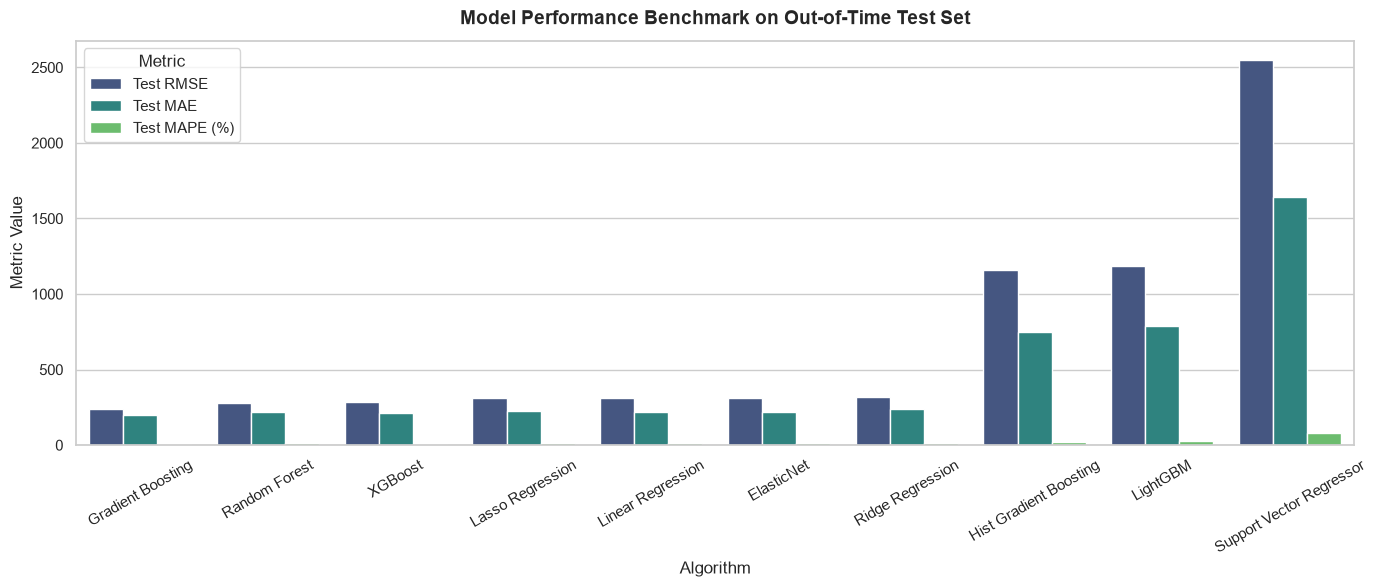

In [6]:
# 1. Benchmark Comparison Bar Chart
fig, ax = src.plot_model_comparison(qtr_benchmark_results)
plt.show()

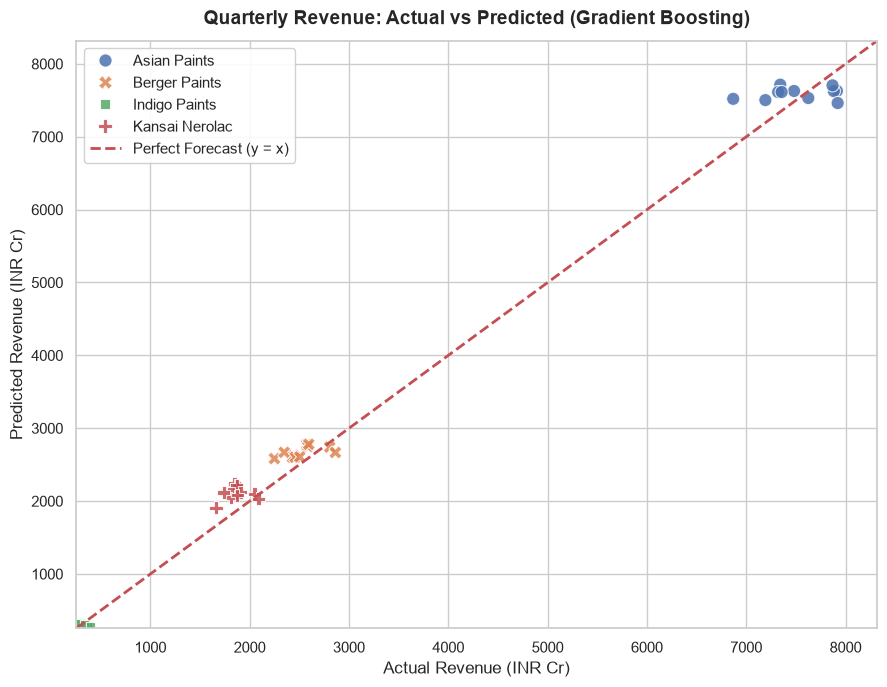

In [7]:
# 2. Actual vs Predicted Scatter Plot for Best Quarterly Model
best_qtr_name = qtr_benchmark_results.iloc[0]['Model']
best_qtr_preds = qtr_predictions[best_qtr_name]

fig, ax = src.plot_actual_vs_predicted(
    y_true=y_test_qtr.values,
    y_pred=best_qtr_preds,
    company_labels=clean_qtr.loc[test_mask_qtr, 'company'],
    title=f"Quarterly Revenue: Actual vs Predicted ({best_qtr_name})"
)
plt.show()

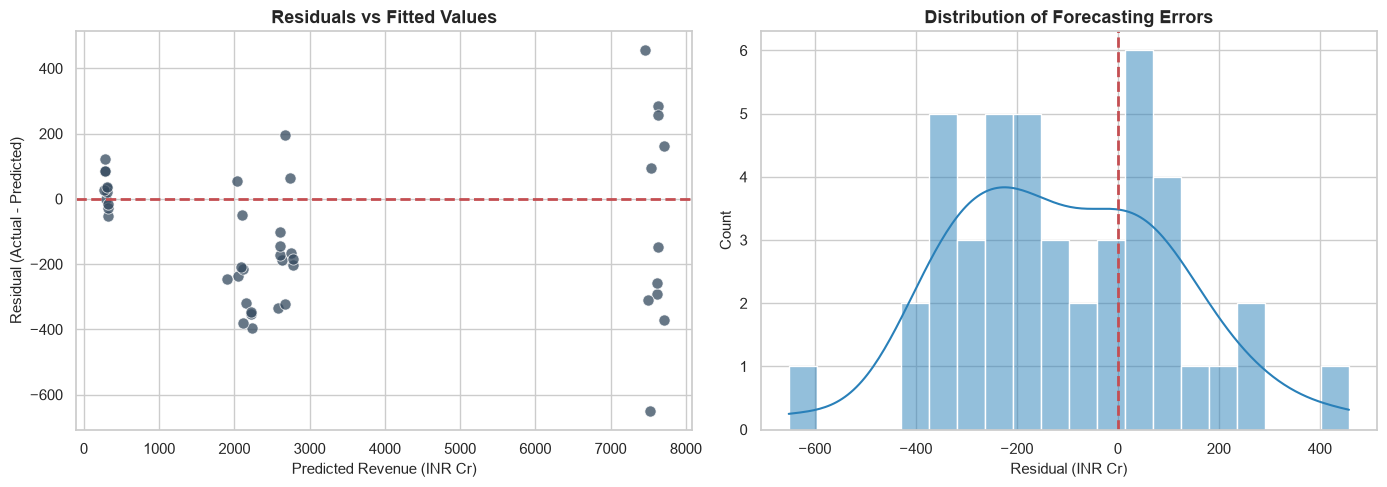

In [8]:
# 3. Residual Diagnostics
fig, (ax1, ax2) = src.plot_residuals(
    y_true=y_test_qtr.values,
    y_pred=best_qtr_preds,
    title=f"Quarterly Residual Diagnostics ({best_qtr_name})"
)
plt.show()

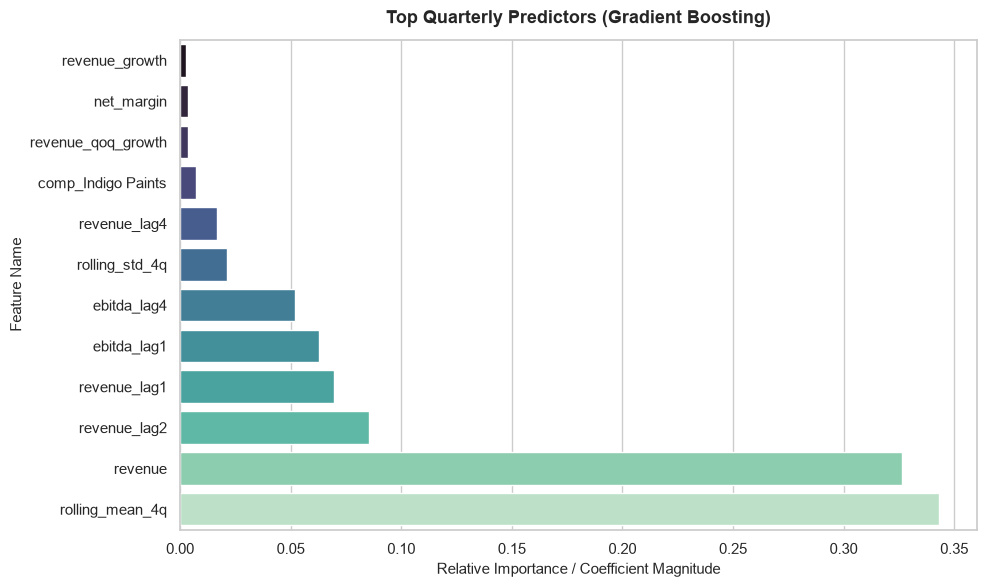

In [9]:
# 4. Top Feature Importances (Seasonal vs Operational vs Trend)
qtr_imp = src.get_feature_importances(qtr_fitted_models[best_qtr_name], all_qtr_cols)
if not qtr_imp.empty:
    fig, ax = src.plot_feature_importances(
        qtr_imp, top_n=12, title=f"Top Quarterly Predictors ({best_qtr_name})"
    )
    plt.show()
else:
    gb_imp = src.get_feature_importances(qtr_fitted_models['Gradient Boosting'], all_qtr_cols)
    fig, ax = src.plot_feature_importances(gb_imp, top_n=12, title="Gradient Boosting Feature Importances")
    plt.show()

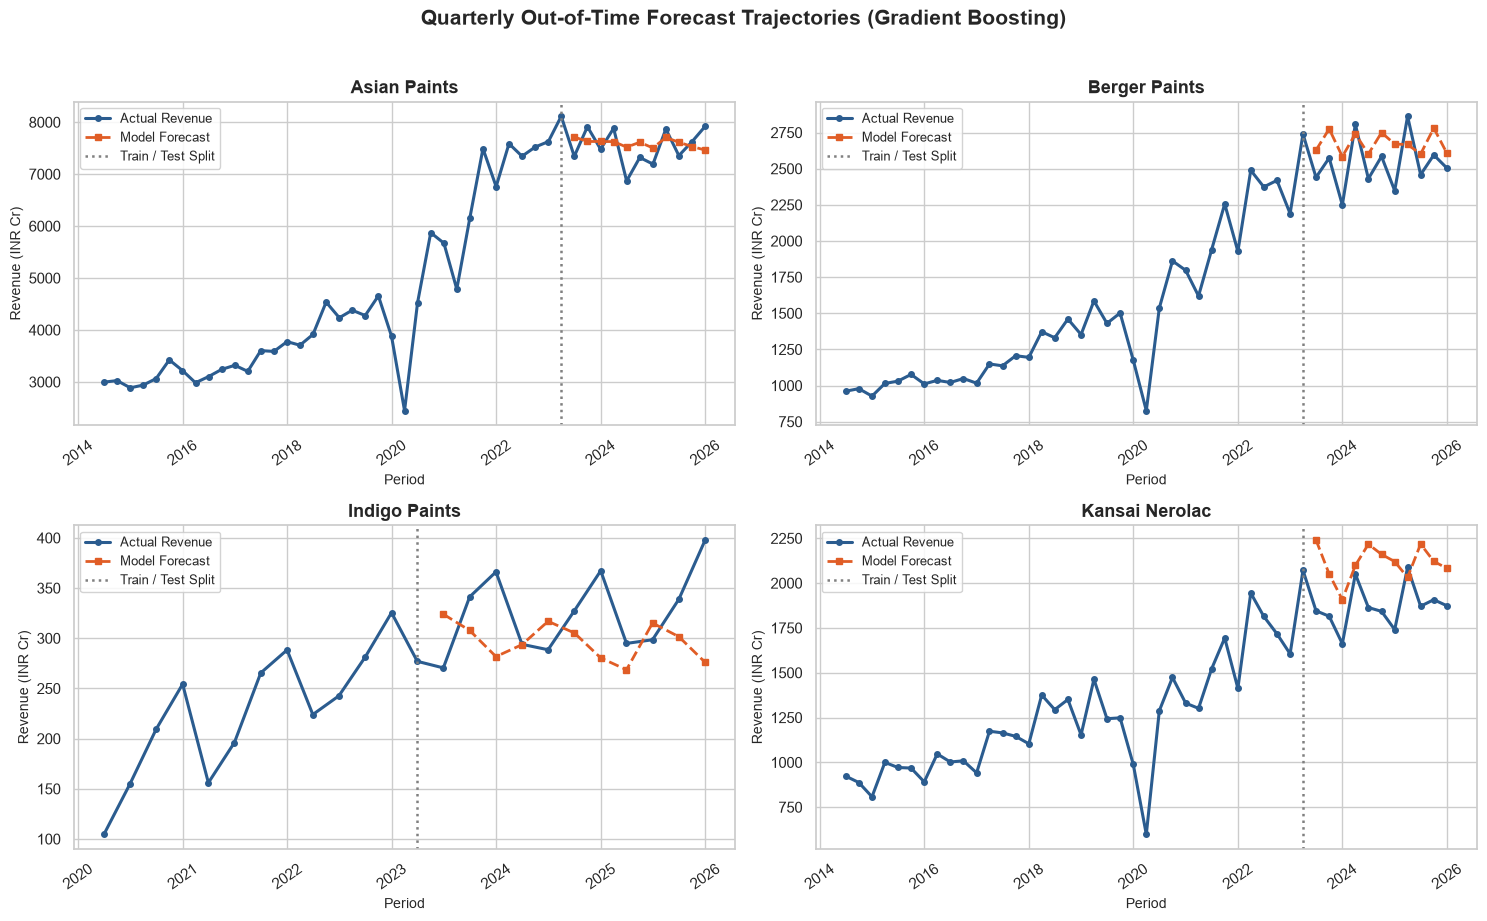

In [10]:
# 5. Out-of-Time Forecast Trajectories by Company
df_eval_qtr = clean_qtr.copy()
df_eval_qtr['predicted_revenue'] = np.nan
df_eval_qtr.loc[test_mask_qtr, 'predicted_revenue'] = best_qtr_preds

fig, axes = src.plot_revenue_trajectories(
    df_eval_qtr,
    date_col='period_end',
    actual_col='target_next_revenue',
    pred_col='predicted_revenue',
    company_col='company',
    split_date='2023-03-31',
    title=f"Quarterly Out-of-Time Forecast Trajectories ({best_qtr_name})"
)
plt.show()

## 6. Forward Projections: Forecasting FY2027 Q1 Revenue
We apply the best quarterly model to the most recent FY2026 Q4 results to forecast **FY2027 Q1 Revenue** for Asian Paints, Berger Paints, Kansai Nerolac, and Indigo Paints.

In [11]:
latest_qtr = df_qtr_feat.groupby('company').tail(1).copy()
X_latest_qtr, _, _, _ = src.prepare_feature_matrix(
    latest_qtr, feature_cols=qtr_feature_cols, target_col="target_next_revenue", drop_na_target=False
)

best_qtr_model = qtr_fitted_models[best_qtr_name]
latest_qtr['forecast_FY2027_Q1_revenue'] = best_qtr_model.predict(X_latest_qtr)
latest_qtr['implied_QoQ_growth_%'] = (
    (latest_qtr['forecast_FY2027_Q1_revenue'] - latest_qtr['revenue']) / latest_qtr['revenue'] * 100.0
)

print("=== OUT-OF-SAMPLE FY2027 Q1 REVENUE FORECAST (INR CRORE) ===")
latest_qtr[['company', 'financial_year', 'quarter', 'revenue', 'forecast_FY2027_Q1_revenue', 'implied_QoQ_growth_%']]

=== OUT-OF-SAMPLE FY2027 Q1 REVENUE FORECAST (INR CRORE) ===


,company,financial_year,quarter,revenue,forecast_FY2027_Q1_revenue,implied_QoQ_growth_%
47,Asian Paints,FY2026,Q4,7920.24,7650.223108,-3.409201
95,Berger Paints,FY2026,Q4,2504.00,2721.252378,8.676213
120,Indigo Paints,FY2026,Q4,397.91,293.651605,-26.201502
168,Kansai Nerolac,FY2026,Q4,1873.44,2229.465887,19.003859
